In [2]:
import pandas as pd
import numpy as np
from scipy.signal import butter, sosfiltfilt
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['font.family']= 'Arial'
mpl.rcParams['font.size']= 14

In [3]:
csv_path = 'data/BTVIZ_2025-04-02.csv'
df = pd.read_csv(csv_path, dtype={"deviceName": str}, low_memory=False)
# Only keep the rows where deviceName is empty
df = df[df["deviceName"].isna()].reset_index(drop=True)
channel_cols = [c for c in df.columns if c.startswith("data_")]
data = df[channel_cols].to_numpy()

# show the first 5 rows of df
print(df.head())

                         id      timestamp  notificationTimestamp deviceName  \
0  2025-04-02T13:58:02.657Z  1743602282657                     28        NaN   
1  2025-04-02T13:58:02.657Z  1743602282657                     29        NaN   
2  2025-04-02T13:58:02.657Z  1743602282657                     88        NaN   
3  2025-04-02T13:58:02.657Z  1743602282657                     88        NaN   
4  2025-04-02T13:58:02.657Z  1743602282657                     88        NaN   

   data_0  data_1  data_2  data_3  data_4  data_5  
0     1.0     2.0     5.0     6.0     6.0     4.0  
1     NaN     NaN     NaN     NaN     NaN     NaN  
2     1.0     2.0     5.0     6.0     6.0     4.0  
3     1.0     2.0     5.0     6.0     6.0     4.0  
4     1.0     2.0     5.0     6.0     6.0     4.0  


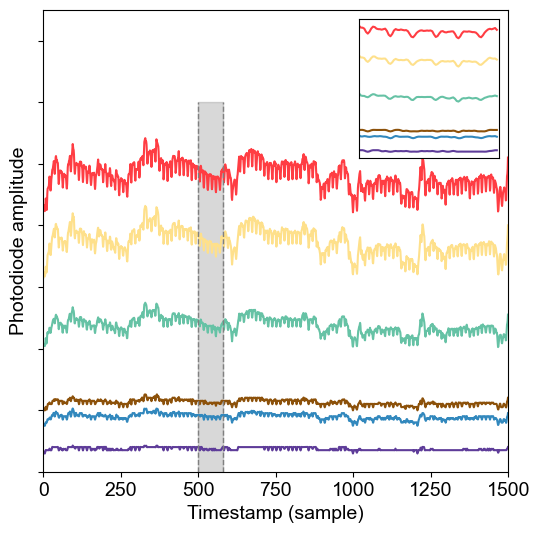

In [4]:
start_stop_pairs = [
    (22500, 24000),
    (23000, 23080),
]

# create two data sections based on the start and stop pairs
data_sections = []
for start, stop in start_stop_pairs:
    data_section = data[start:stop]
    data_sections.append(data_section)

# Sampling frequency and filter parameters
fs = 60.0  # Sampling frequency in Hz
fc = 15.0  # Cutoff frequency in Hz
order = 2  # Filter order

# Purple, Blue, Green, Yellow, Red, Brown
colors = ['#5e3c99', '#3288bd', '#66c2a5', '#fee08b', '#ff3d43', '#8c510a'] 

# Define Butterworth filter
sos = butter(order, fc, fs=fs, btype='low', output='sos')

# Filter the data sections
data_sections_filtered = []
for data_section in data_sections:
    filtered_data_section = sosfiltfilt(sos, data_section, axis=0)
    data_sections_filtered.append(filtered_data_section)

# Add 5 to the last channel of all sections
for i in range(len(data_sections_filtered)):
    if data_sections_filtered[i].shape[1] > 0:
        # Add 5 to the last channel of the filtered data
        data_sections_filtered[i][:, -1] += 5

# Plot the filtered data with the first plot as an inset
fig, ax = plt.subplots(figsize=(6, 6))

# Main plot (second data section)
for i in range(data_sections_filtered[0].shape[1]):
    if i < len(colors):
        ax.plot(data_sections_filtered[0][:, i], color=colors[i])
ax.set_xlim(0, data_sections_filtered[0].shape[0])
ax.set_ylim(0, 150)
ax.set_yticklabels([])
ax.set_xlabel('Timestamp (sample)')
ax.set_ylabel('Photodiode amplitude')

# Inset plot (first data section)
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
ax_inset = inset_axes(ax, width="30%", height="30%", loc="upper right")  # Adjust size and location
for i in range(data_sections_filtered[1].shape[1]):
    if i < len(colors):
        ax_inset.plot(data_sections_filtered[1][:, i], color=colors[i])
ax_inset.set_xlim(0, data_sections_filtered[1].shape[0])
ax_inset.tick_params(axis='both', which='major', labelsize=8)

ax_inset.set_xticks([])
ax_inset.set_yticks([])

# Add vertical lines and shaded area to highlight the selected region
highlight_start = start_stop_pairs[1][0] - start_stop_pairs[0][0]
highlight_end = start_stop_pairs[1][1] - start_stop_pairs[0][0]

ymax = 120 / ax.get_ylim()[1]
ax.axvline(x=highlight_start, ymax=ymax, color='gray', linestyle='--', linewidth=1)
ax.axvline(x=highlight_end, ymax=ymax, color='gray', linestyle='--', linewidth=1)
ax.axvspan(highlight_start, highlight_end, color='gray', alpha=0.3, ymax=ymax)

# plt.savefig('mode1.svg', dpi=300, bbox_inches='tight')
plt.show()

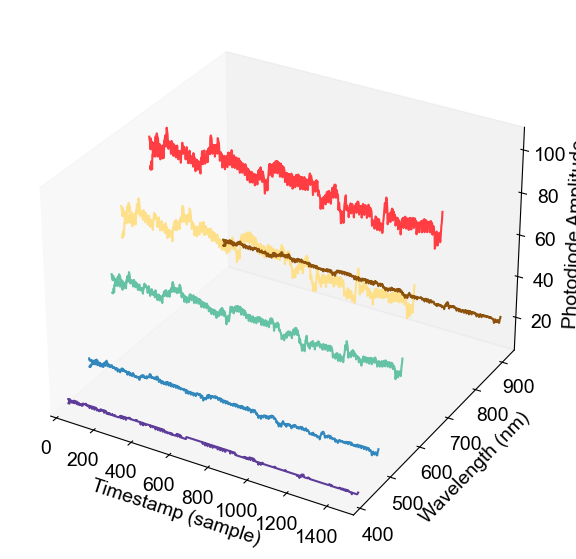

In [12]:
from mpl_toolkits.mplot3d import Axes3D

# Reference map for wavelengths
wavelength_map = {'data_0': 415, 'data_1': 480, 'data_2': 555, 'data_3': 590, 'data_4': 680, 'data_5': 910}
wavelengths = list(wavelength_map.values())

# Create a 3D plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Colors for each channel
colors = ['#5e3c99', '#3288bd', '#66c2a5', '#fee08b', '#ff3d43', '#8c510a']

# Plot each channel as a 2D plot in 3D space
for section_idx, data_section in enumerate(data_sections_filtered):
    timestamps = np.arange(data_section.shape[0])  # X-axis: sample indices
    for channel_idx in range(data_section.shape[1]):
        if channel_idx < len(wavelengths):  # Ensure we have a wavelength for the channel
            z_values = data_section[:, channel_idx]  # Z-axis: filtered data values
            y_values = np.full_like(timestamps, wavelengths[channel_idx])  # Y-axis: wavelength
            x_values = timestamps  # X-axis: timestamps
            
            # Plot the 2D line in 3D space
            ax.plot(x_values, y_values, z_values, color=colors[channel_idx])

# Remove the grid
ax.grid(False)

# Add labels
ax.set_xlim(0, data_sections_filtered[0].shape[0])
ax.set_xlabel('Timestamp (sample)')
ax.set_ylabel('Wavelength (nm)')
ax.set_zlabel('Photodiode Amplitude')

# Show the plot
plt.show()

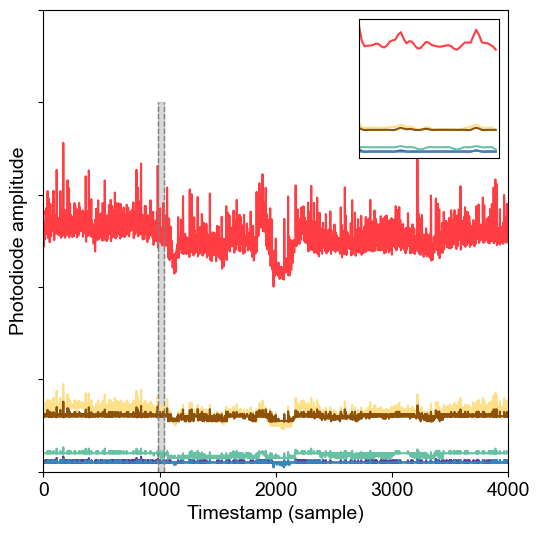

In [ ]:
start_stop_pairs = [
    (310000, 314000),
    (310990, 311040),
]


# create two data sections based on the start and stop pairs
data_sections = []
for start, stop in start_stop_pairs:
    data_section = data[start:stop]
    data_sections.append(data_section)

# Sampling frequency and filter parameters
fs = 60.0  # Sampling frequency in Hz
fc = 15.0  # Cutoff frequency in Hz
order = 2  # Filter order

# Purple, Blue, Green, Yellow, Red, Brown
colors = ['#5e3c99', '#3288bd', '#66c2a5', '#fee08b', '#ff3d43', '#8c510a'] 

# Define Butterworth filter
sos = butter(order, fc, fs=fs, btype='low', output='sos')

# Filter the data sections
data_sections_filtered = []
for data_section in data_sections:
    filtered_data_section = sosfiltfilt(sos, data_section, axis=0)
    data_sections_filtered.append(filtered_data_section)

# Add 5 to the last channel of all sections
for i in range(len(data_sections_filtered)):
    if data_sections_filtered[i].shape[1] > 0:
        # Add 5 to the last channel of the filtered data
        data_sections_filtered[i][:, -1] += 5

# Plot the filtered data with the first plot as an inset
fig, ax = plt.subplots(figsize=(6, 6))

# Main plot (second data section)
for i in range(data_sections_filtered[0].shape[1]):
    if i < len(colors):
        ax.plot(data_sections_filtered[0][:, i], color=colors[i])
ax.set_xlim(0, data_sections_filtered[0].shape[0])
ax.set_ylim(0, 100)
ax.set_yticklabels([])
ax.set_xlabel('Timestamp (sample)')
ax.set_ylabel('Photodiode amplitude')

# Inset plot (first data section)
ax_inset = inset_axes(ax, width="30%", height="30%", loc="upper right")  # Adjust size and location
for i in range(data_sections_filtered[1].shape[1]):
    if i < len(colors):
        ax_inset.plot(data_sections_filtered[1][:, i], color=colors[i])
ax_inset.set_xlim(0, data_sections_filtered[1].shape[0])
ax_inset.tick_params(axis='both', which='major', labelsize=8)

ax_inset.set_xticks([])
ax_inset.set_yticks([])

# Add vertical lines and shaded area to highlight the selected region
highlight_start = start_stop_pairs[1][0] - start_stop_pairs[0][0]
highlight_end = start_stop_pairs[1][1] - start_stop_pairs[0][0]

ymax = 80 / ax.get_ylim()[1]
ax.axvline(x=highlight_start, ymax=ymax, color='gray', linestyle='--', linewidth=1)
ax.axvline(x=highlight_end, ymax=ymax, color='gray', linestyle='--', linewidth=1)
ax.axvspan(highlight_start, highlight_end, color='gray', alpha=0.3, ymax=ymax)

# plt.savefig('mode2.svg', dpi=300, bbox_inches='tight')
plt.show()